## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [94]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import statsmodels.api as sm

In [4]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [90]:
df_numerical = df.select_dtypes("number")
df_numerical = df_numerical.drop(columns=['uid'])
df_numerical

,stars,reviews,price,boughtInLastMonth
0,4.7,15308,21.99,0
1,4.7,98099,23.99,0
2,4.7,15308,21.99,0
3,4.7,7205,31.99,0
4,4.6,1881,17.99,0
...,...,...,...,...
2443646,0.0,0,22.34,0
2443647,0.0,0,97.99,0
2443648,0.0,0,52.99,0
2443649,4.3,404,79.99,0


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [38]:
# 1.1 Crosstab Analysis
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [35]:
# Calculate proportion of True best-sellers per category
crosstab['proportion_best_seller'] = (crosstab[True] / (crosstab[True] + crosstab[False]))
crosstab1.sort_values(by='proportion_best_seller', ascending=False)

isBestSeller,False,True,proportion_best_seller
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


In [36]:
# 1.2 Statistical Tests
# Perform Chi-square test
chi2, p, dof, expected = chi2_contingency(crosstab)

print("Chi2 Statistic:", chi2)
print("p-value:", p)

Chi2 Statistic: 36684.23786636857
p-value: 0.0


Tests the independence of two categorical variables by comparing observed frequencies to expected frequencies.

- The chi-square test is a statistical test used to **determine whether there is a significant association between two categorical variables**.
- Interpretation: if p-value < 0.05, this suggests that there is a significant association between the categorical variables. P-value >= 0.05, indicates that there is not enough evidence to conclude a significant association between the variables.

Given the low ( p )-value, we reject the null hypothesis.

In [39]:
# Perform "cramer" method for crosstab
association(crosstab, method = "cramer")

0.1222829439760564

While the Chi-square test informs us about the independence of two categorical variables, Cramér's V measures the strength of the association between them. 

- Cramer's V is a measure of association used to **quantify the strength of the relationship between categorical variables**. 
- Interpretation: Cramer's V ranges from 0 to 1, where **0 indicates no association, and 1 represents a perfect association between the variables**. A higher value of Cramer's V indicates a stronger relationship between the categorical variables.

The Cramér's V value of 0.122 suggests a weak association between the two variables.

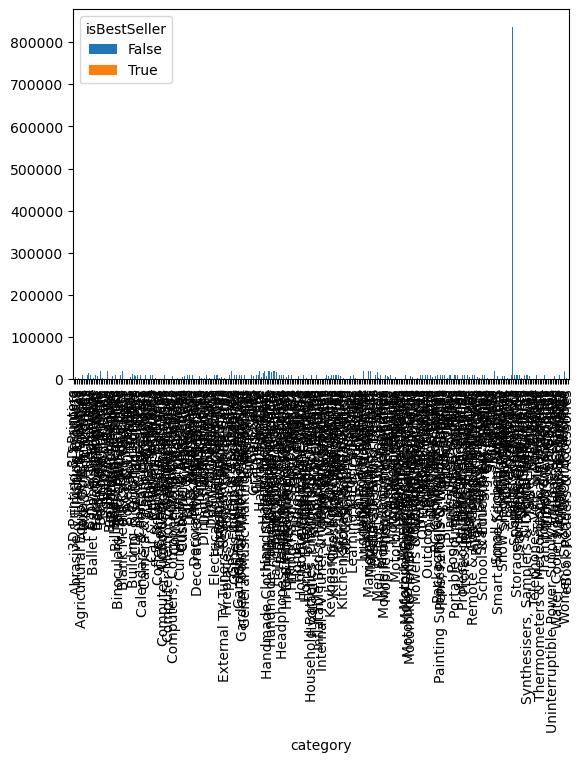

In [40]:
# 1.3 Visualizations
# Plotting a stacked bar chart for the 'crosstab_result' data
crosstab.plot(kind="bar", stacked=True)
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [42]:
# 2.0 Preliminary Step: Remove outliers in product prices.
# Calculate Q1, Q3 and IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for non-outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter dataframe
df_no = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print("Original shape:", df.shape)
print("After removing outliers:", df_no.shape)

Original shape: (2443651, 9)
After removing outliers: (2115963, 9)


In [44]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [71]:
# Get top 20 categories by count
top20_categories = df_no['category'].value_counts().head(20).index
top10_categories = df_no['category'].value_counts().head(10).index

# Filter dataframe to include only those categories
df_top20 = df_no[df_no['category'].isin(top20_categories)]
df_top10 = df_no[df_no['category'].isin(top10_categories)]

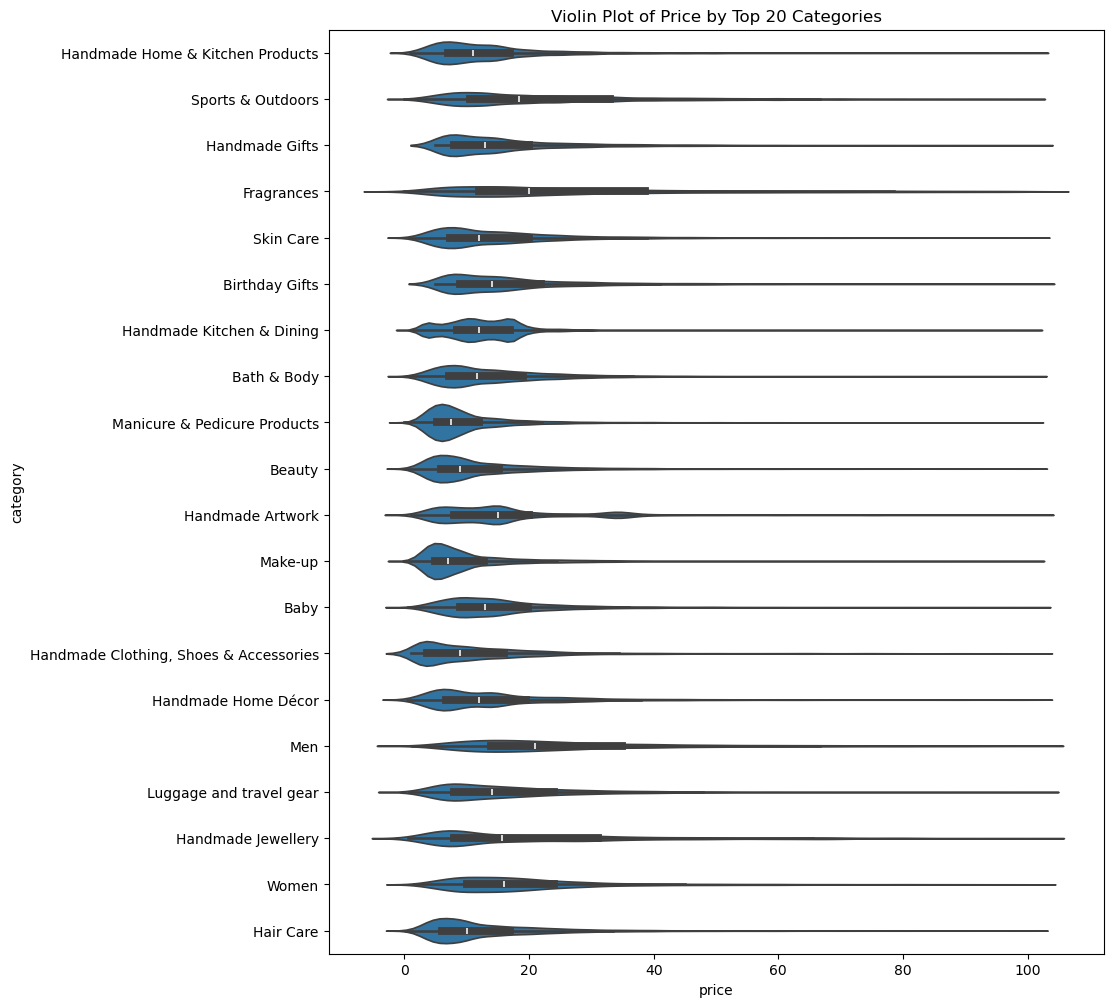

In [51]:
# 2.1 Viloin plot
# Use a violin plot to visualize the distribution of price across different product categories. 
# Filter out the top 20 categories based on count for better visualization.
# Which product category tends to have the highest median price? Don't filter here by top categories.
plt.figure(figsize=(10, 12))
sns.violinplot(data=df_top20, x='price', y='category')
plt.title("Violin Plot of Price by Top 20 Categories")
plt.show()

In [57]:
# Calculate median price per category
median_prices = df_no.groupby("category")["price"].median().sort_values(ascending=False)
median_prices

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

In [61]:
# 2.2 Bar Charts:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

# Get top 10 categories by count
top10_categories = df_no['category'].value_counts().head(10).index

# Filter dataframe to include only those categories
avg_prices = df_no[df_no['category'].isin(top10_categories)].groupby('category')["price"].mean().sort_values(ascending=False)
avg_prices

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

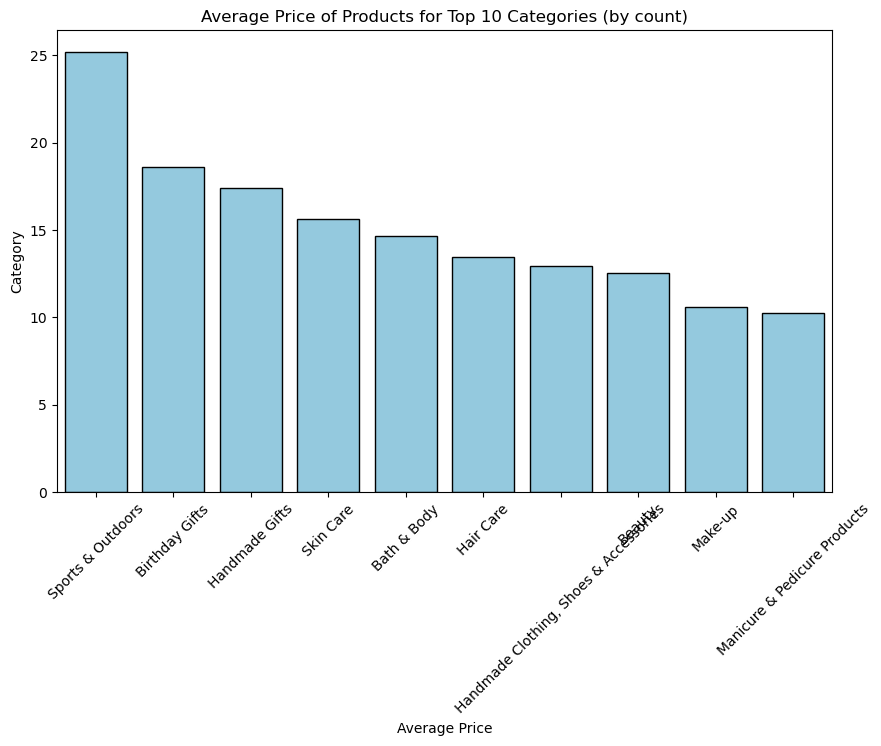

In [66]:
plt.figure(figsize=(10,6))
sns.barplot(x=avg_prices.index, y=avg_prices.values, color="skyblue", edgecolor="black")

plt.title("Average Price of Products for Top 10 Categories (by count)")
plt.xlabel("Average Price")
plt.ylabel("Category")
plt.xticks(rotation=45)
plt.show()

In [68]:
# 2.2 Which product category commands the highest average price? Don't filter here by top categories.
df_no.groupby('category')["price"].mean().sort_values(ascending=False)

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

/var/folders/dr/39536wgj4mn3x17g766yjxlr0000gn/T/ipykernel_67765/286160447.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")


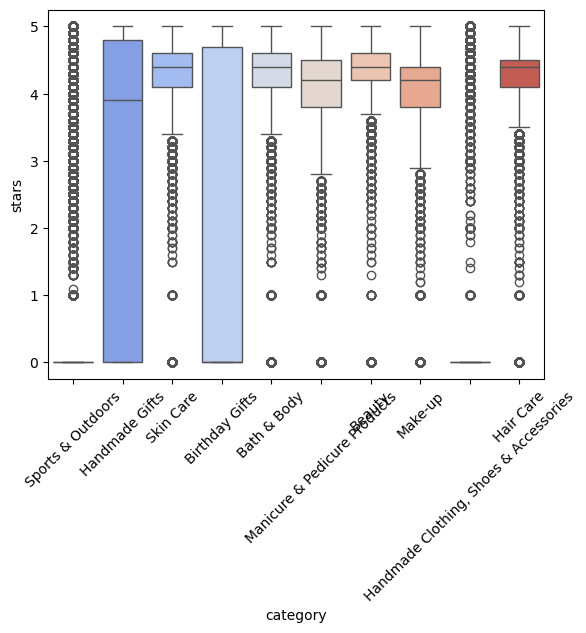

In [73]:
# 2.3 Box Plots:
# Visualize the distribution of product ratings based on their category using side-by-side box plots. 
# Filter out the top 10 categories based on count for better visualization.

sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=45)
plt.show()

In [69]:
# 2.3 Which category tends to receive the highest median rating from customers? 
# Don't filter here by top categories.
df_no.groupby('category')["stars"].mean().sort_values(ascending=False)

category
Luxury Food & Drink                       4.544140
Grocery                                   4.469414
Laptop Accessories                        4.449600
Health & Personal Care                    4.439549
Arts & Crafts                             4.432942
                                            ...   
Boxing Shoes                              0.160470
Motorbike Handlebars, Controls & Grips    0.134289
Motorbike Electrical & Batteries          0.105697
3D Printing & Scanning                    0.094067
CD, Disc & Tape Players                   0.048834
Name: stars, Length: 296, dtype: float64

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

In [81]:
# 3.1 Correlation Coefficients, Pearson:
correlation1 = df['price'].corr(df['stars'])
correlation2 = df_no['price'].corr(df_no['stars'])
print(f"Correlation of original df: {correlation1.round(2)}")
print(f"Correlation of df without outliers: {correlation2.round(2)}")

Correlation of original df: -0.12
Correlation of df without outliers: -0.08


In [82]:
# 3.1 Correlation Coefficients, Spearman:
correlation1 = df['price'].corr(df['stars'], method='spearman')
correlation2 = df_no['price'].corr(df_no['stars'], method='spearman')
print(f"Correlation of original df: {correlation1.round(2)}")
print(f"Correlation of df without outliers: {correlation2.round(2)}")

Correlation of original df: -0.13
Correlation of df without outliers: -0.07


Insights:

The Pearson correlation suggests a weak negative linear relationship between the price and stars.

The Spearman correlation suggests a weak monotonic linear relationship between the price and stars.

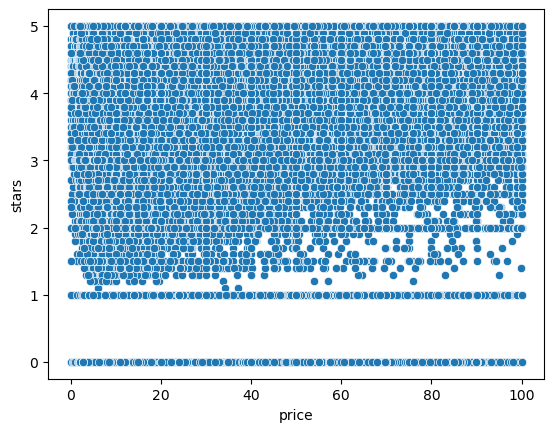

In [83]:
# 3.2 Visualizations:
# Use a scatter plot to visualize the relationship between product rating and price. 
# What patterns can you observe?

sns.scatterplot(data=df_no, x='price', y='stars')
plt.show()

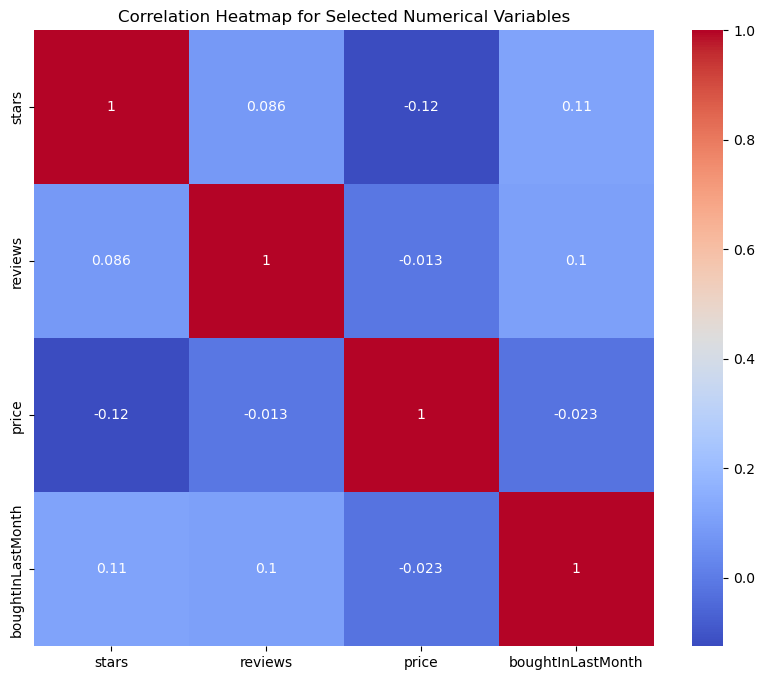

In [93]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(10, 8))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

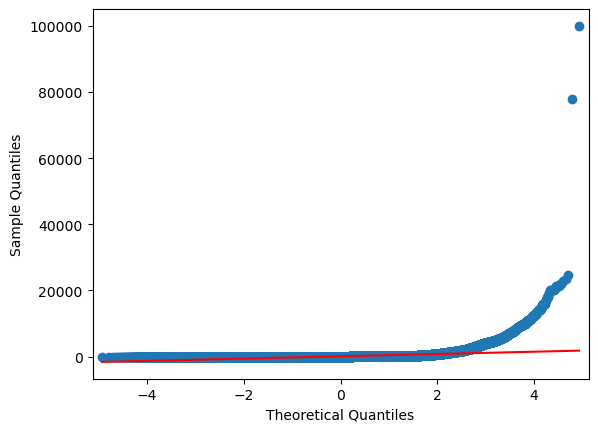

In [96]:
# 3.2 Examine if product prices typically follow a normal distribution using a QQ plot. 
sm.qqplot(df['price'], line='s')
plt.show()

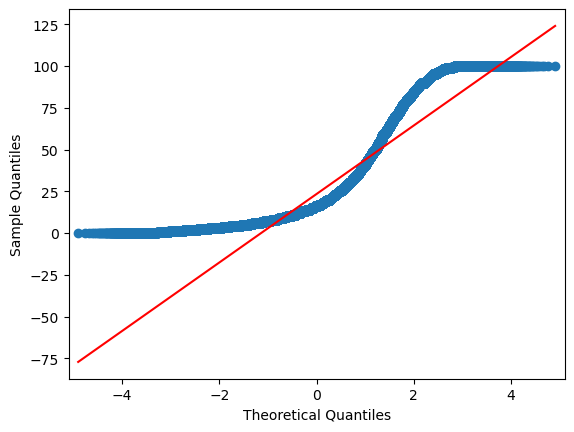

In [97]:
# 3.2 Examine if product prices typically follow a normal distribution using a QQ plot. 
sm.qqplot(df_no['price'], line='s')
plt.show()